In [1]:
# Setup
import glob
import json

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

RESULTS_DIR = "Results"
METRIC = "scaled MAE (all)"
BASELINE = "last-value baseline"
ACCURACY_COLUMNS = ["MAE", "scaled MAE (nominal)", "scaled MAE (off nominal)", "scaled MAE (all)",
                    "baseline (nominal)", "baseline (off nominal)", "baseline (all)"]


In [2]:
# Load results
def read_group(group):
    values = {}
    for col in group:
        values[col] = group[col][()]
    return values


tables = {}
forecasts = {}
settings = {}
for path in sorted(glob.glob(f"{RESULTS_DIR}/setpointforecast_*.h5")):
    with h5py.File(path, "r") as f:
        model = f.attrs["model"]
        settings[model] = json.loads(f.attrs["settings"])

        table = pd.DataFrame(index=f["variable"].asstr()[()])
        table["description"] = f["description"].asstr()[()]
        for name in ACCURACY_COLUMNS:
            table[name] = f[name][()]
        tables[model] = table

        forecasts[model] = {
            "time_h": f["time_h"][()],
            "off_nominal": f["off_nominal"][()],
            "context_time_h": f["context_time_h"][()],
            "forecast": read_group(f["forecast"]),
            "lower": read_group(f["lower"]),
            "upper": read_group(f["upper"]),
            "actual": read_group(f["actual"]),
            "context": read_group(f["context"]),
        }

MODELS = list(tables)
print(f"Loaded {len(MODELS)} models: {', '.join(MODELS)}")

# Check that all models used the same data and forecast window
for key in ["data_file", "event_index", "split", "horizon"]:
    values = set()
    for model in MODELS:
        values.add(str(settings[model][key]))
    if len(values) > 1:
        print(f"Warning: the models differ in {key}: {', '.join(sorted(values))}")

pd.DataFrame(settings).T


Loaded 3 models: ARX + Ridge, Chronos-2, TimesFM 3.0


,data_file,event_index,split,horizon,future_covariates,past_only_covariates
ARX + Ridge,tep_sp_spaced_6min_noisy.h5,72,6300,50,"[sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15,...",[]
Chronos-2,tep_sp_spaced_6min_noisy.h5,74,6488,50,"[sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15,...",[]
TimesFM 3.0,tep_sp_spaced_6min_noisy.h5,74,6488,50,"[sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15,...",[]


In [3]:
# Scores per variable (xmeas_1 ... xmv_12)
first = MODELS[0]
descriptions = tables[first]["description"]

scores = pd.DataFrame(index=tables[first].index)
for model in MODELS:
    scores[model] = tables[model][METRIC]
scores[BASELINE] = tables[first][METRIC.replace("scaled MAE", "baseline")]
scores = scores.dropna()

ALL = MODELS + [BASELINE]
COLORS = {}
for i, model in enumerate(MODELS):
    COLORS[model] = f"C{i}"
COLORS[BASELINE] = "gray"

table = scores.copy()
table.insert(0, "description", descriptions)
print(f"{METRIC} per variable, lower is better")
table.round(3)


scaled MAE (all) per variable, lower is better


,description,ARX + Ridge,Chronos-2,TimesFM 3.0,last-value baseline
xmeas_1,A feed (kscmh),0.683,0.560,0.513,0.811
xmeas_2,D feed (kg/h),0.723,0.764,0.791,0.720
xmeas_3,E feed (kg/h),0.483,0.664,0.739,0.562
xmeas_4,A and C feed (kscmh),0.740,0.727,0.813,1.326
xmeas_5,Recycle flow (kscmh),0.842,0.770,0.769,0.907
xmeas_6,Reactor feed rate (kscmh),0.702,0.920,0.962,0.742
xmeas_7,Reactor pressure (kPa),0.159,0.457,0.484,0.457
xmeas_8,Reactor level (%),0.627,0.724,0.777,0.708
xmeas_9,Reactor temperature (C),0.297,0.275,0.275,0.339
xmeas_10,Purge rate (kscmh),0.225,1.003,0.418,0.443


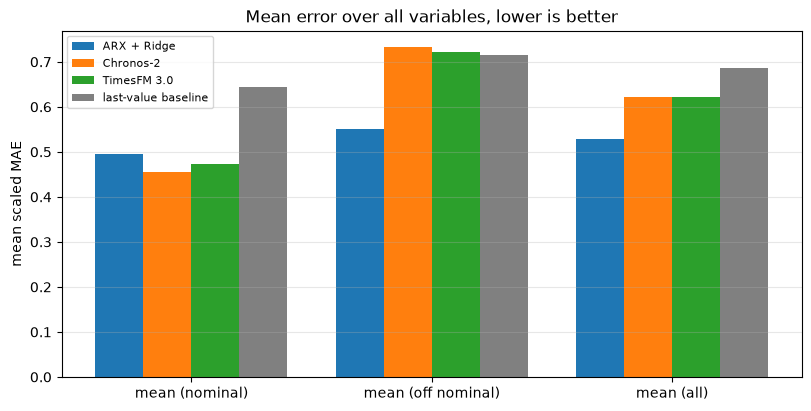

,mean (nominal),mean (off nominal),mean (all),median (all),best on (variables)
model,,,,,
ARX + Ridge,0.495,0.550,0.528,0.548,28
Chronos-2,0.455,0.733,0.622,0.616,7
TimesFM 3.0,0.473,0.721,0.622,0.636,7
last-value baseline,0.644,0.716,0.687,0.681,10


In [4]:
# Summary
best_model = scores[ALL].idxmin(axis=1)   # model with the lowest error for each variable

rows = []
for model in ALL:
    if model == BASELINE:
        table, prefix = tables[first], "baseline"
    else:
        table, prefix = tables[model], "scaled MAE"
    rows.append({
        "model": model,
        "mean (nominal)": table[f"{prefix} (nominal)"].mean(),
        "mean (off nominal)": table[f"{prefix} (off nominal)"].mean(),
        "mean (all)": table[f"{prefix} (all)"].mean(),
        "median (all)": table[f"{prefix} (all)"].median(),
        "best on (variables)": (best_model == model).sum(),
    })
summary = pd.DataFrame(rows).set_index("model").sort_values("mean (all)")

# Mean error per model, for the nominal, off-nominal and all samples
phases = ["mean (nominal)", "mean (off nominal)", "mean (all)"]
bar_width = 0.8 / len(ALL)
x = np.arange(len(phases))

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for i, model in enumerate(ALL):
    shift = (i - (len(ALL) - 1) / 2) * bar_width
    ax.bar(x + shift, summary.loc[model, phases], width=bar_width, color=COLORS[model], label=model)
ax.set_xticks(x)
ax.set_xticklabels(phases)
ax.set_ylabel("mean scaled MAE")
ax.set_title("Mean error over all variables, lower is better")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")
plt.show()

summary.round(3)


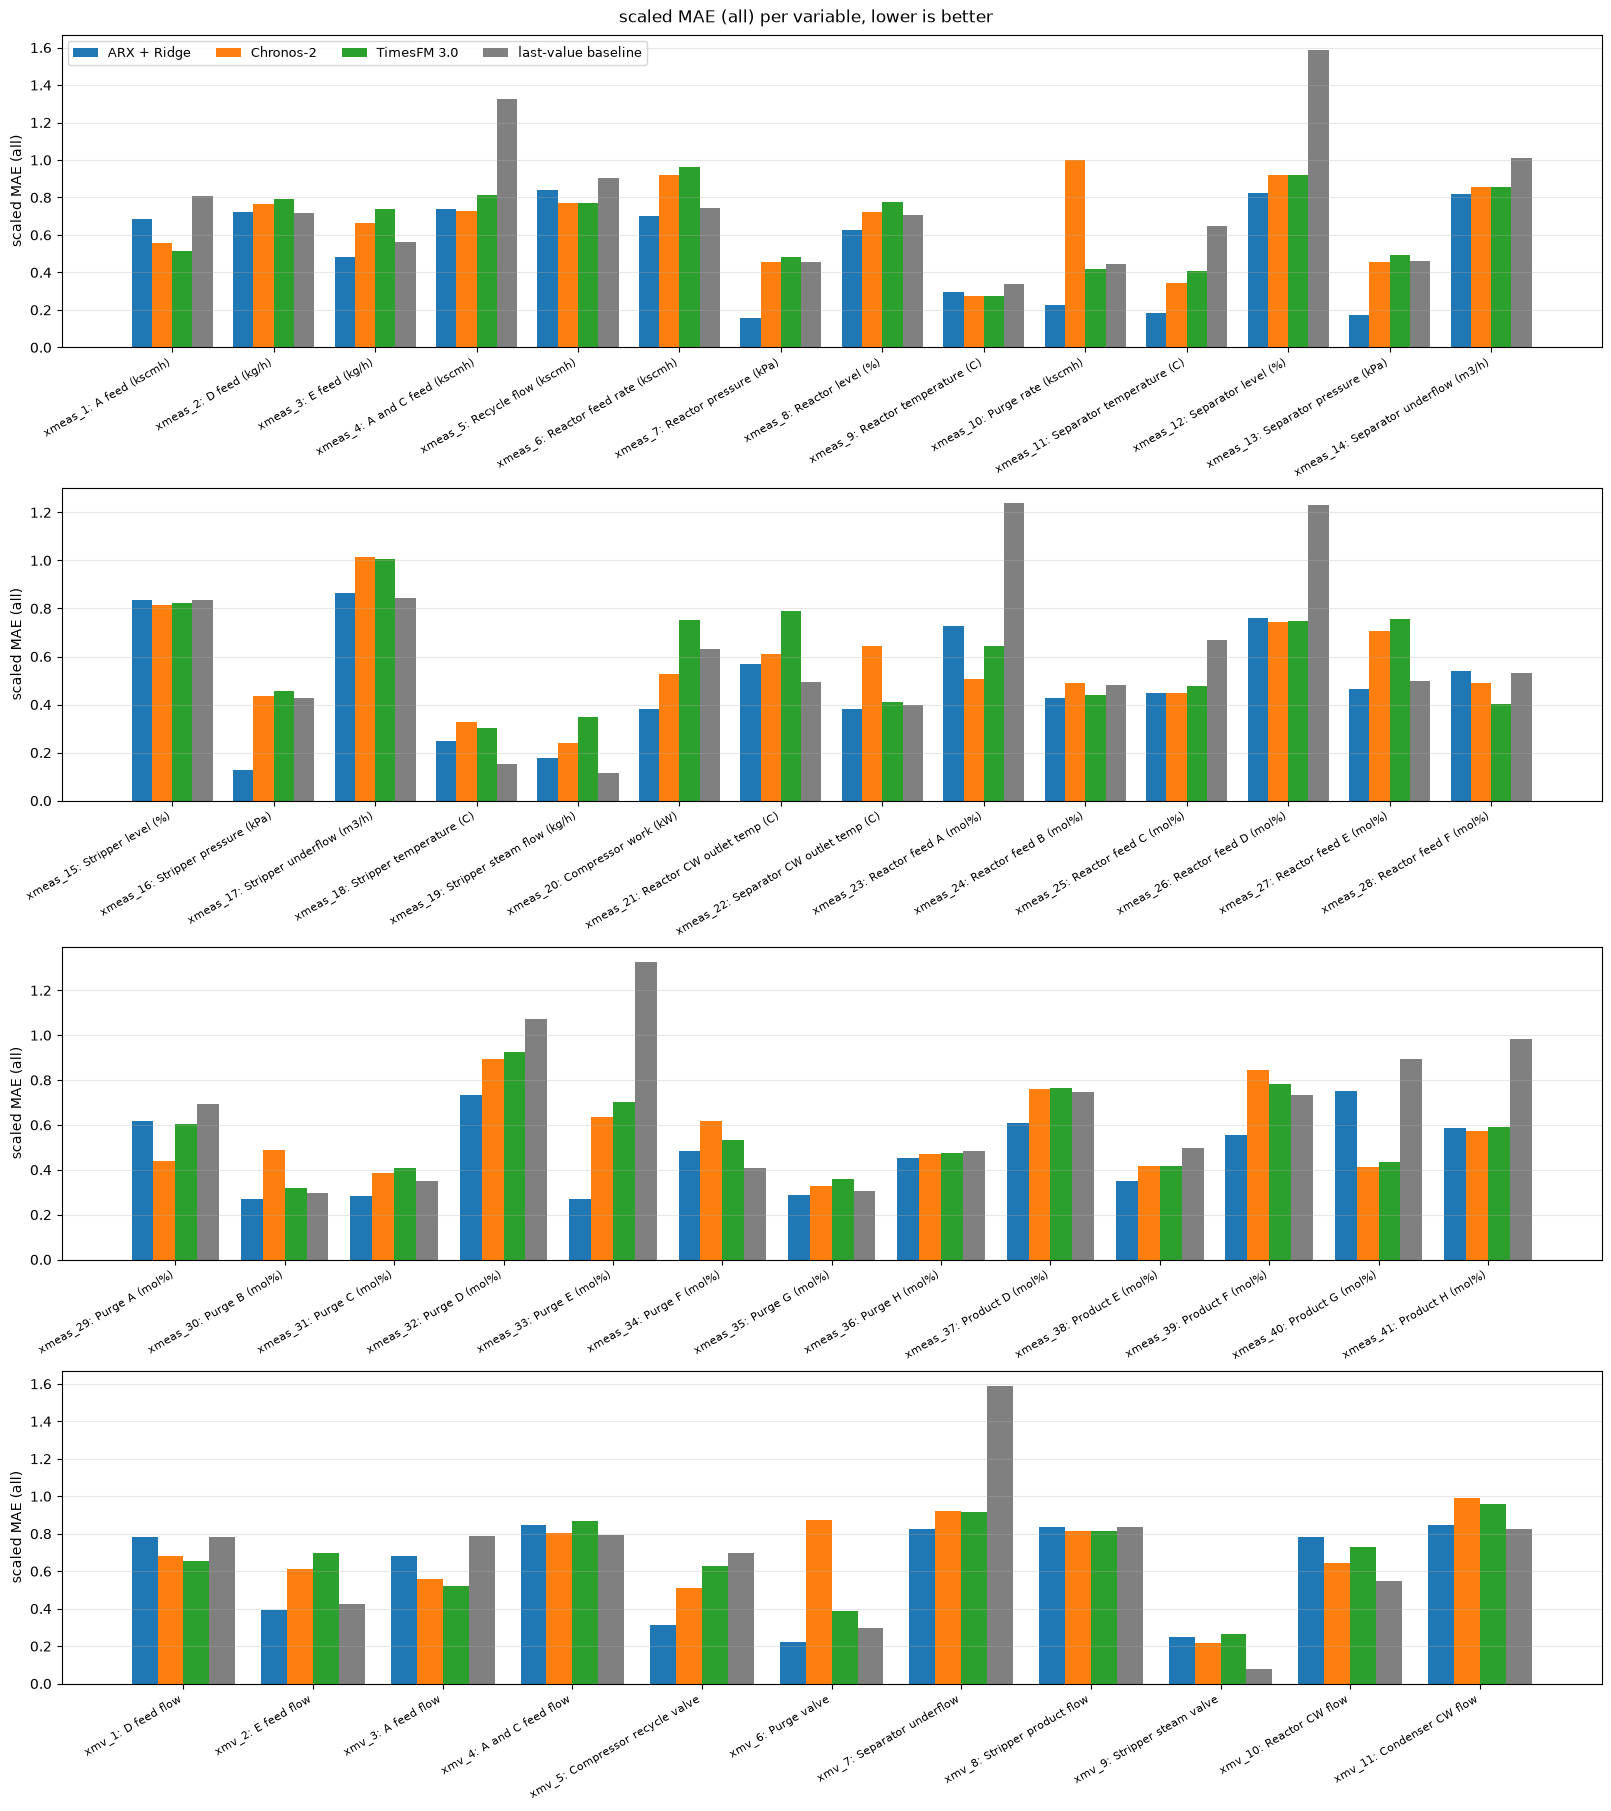

In [5]:
# Error per variable, models side by side
xmeas = [v for v in scores.index if v.startswith("xmeas")]
xmv = [v for v in scores.index if v.startswith("xmv")]
panels = [xmeas[0:14], xmeas[14:28], xmeas[28:], xmv]

bar_width = 0.8 / len(ALL)
fig, axes = plt.subplots(len(panels), 1, figsize=(16, 4.5 * len(panels)), layout="constrained")
for ax, names in zip(axes, panels):
    x = np.arange(len(names))
    for i, model in enumerate(ALL):
        shift = (i - (len(ALL) - 1) / 2) * bar_width
        ax.bar(x + shift, scores.loc[names, model], width=bar_width, color=COLORS[model], label=model)

    labels = []
    for v in names:
        labels.append(f"{v}: {descriptions[v]}")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=8)
    ax.set_ylabel(METRIC)
    ax.grid(alpha=0.3, axis="y")
axes[0].legend(fontsize=9, ncols=len(ALL))
fig.suptitle(f"{METRIC} per variable, lower is better")
plt.show()


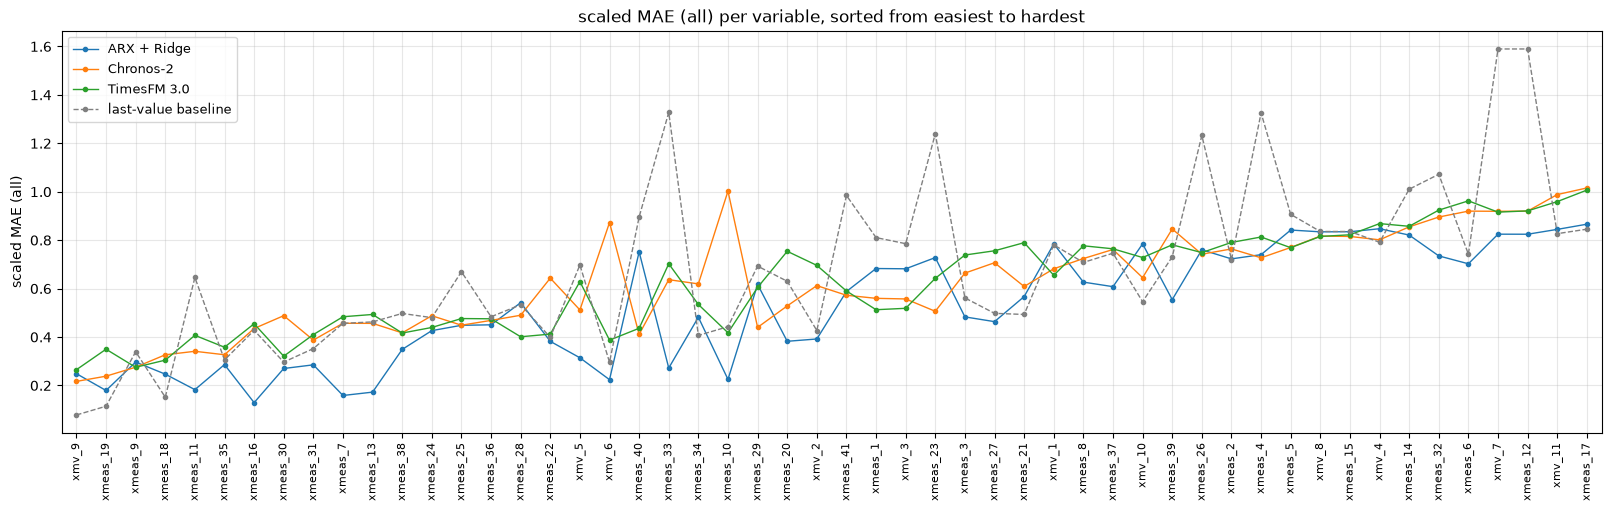

,description,ARX + Ridge,Chronos-2,TimesFM 3.0,last-value baseline,best model
xmv_9,Stripper steam valve,0.249,0.217,0.265,0.078,last-value baseline
xmeas_19,Stripper steam flow (kg/h),0.179,0.238,0.350,0.114,last-value baseline
xmeas_9,Reactor temperature (C),0.297,0.275,0.275,0.339,TimesFM 3.0
xmeas_18,Stripper temperature (C),0.247,0.327,0.305,0.152,last-value baseline
xmeas_11,Separator temperature (C),0.183,0.341,0.407,0.646,ARX + Ridge
xmeas_35,Purge G (mol%),0.286,0.327,0.358,0.305,ARX + Ridge
xmeas_16,Stripper pressure (kPa),0.129,0.435,0.455,0.428,ARX + Ridge
xmeas_30,Purge B (mol%),0.270,0.488,0.321,0.296,ARX + Ridge
xmeas_31,Purge C (mol%),0.285,0.387,0.410,0.352,ARX + Ridge
xmeas_7,Reactor pressure (kPa),0.159,0.457,0.484,0.457,ARX + Ridge


In [6]:
# Variables sorted by error
order = scores[MODELS].mean(axis=1).sort_values().index
sorted_scores = scores.loc[order, ALL]
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(16, 5), layout="constrained")
for model in ALL:
    if model == BASELINE:
        style = "--"
    else:
        style = "-"
    ax.plot(x, sorted_scores[model], style, marker="o", ms=3, lw=1, color=COLORS[model], label=model)
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=90, fontsize=8)
ax.set_xlim(-0.5, len(order) - 0.5)
ax.set_ylabel(METRIC)
ax.set_title(f"{METRIC} per variable, sorted from easiest to hardest")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.show()

table = sorted_scores.copy()
table.insert(0, "description", descriptions)
table["best model"] = best_model
table.round(3)


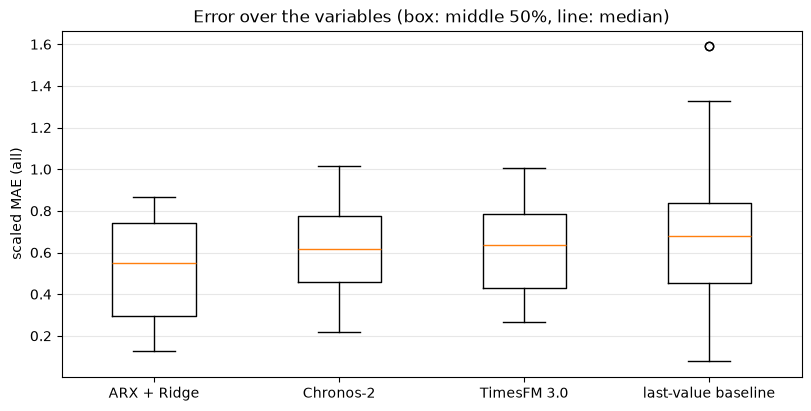

In [7]:
# Spread of the error over the variables
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.boxplot([scores[model] for model in ALL], tick_labels=ALL)
ax.set_ylabel(METRIC)
ax.set_title("Error over the variables (box: middle 50%, line: median)")
ax.grid(alpha=0.3, axis="y")
plt.show()


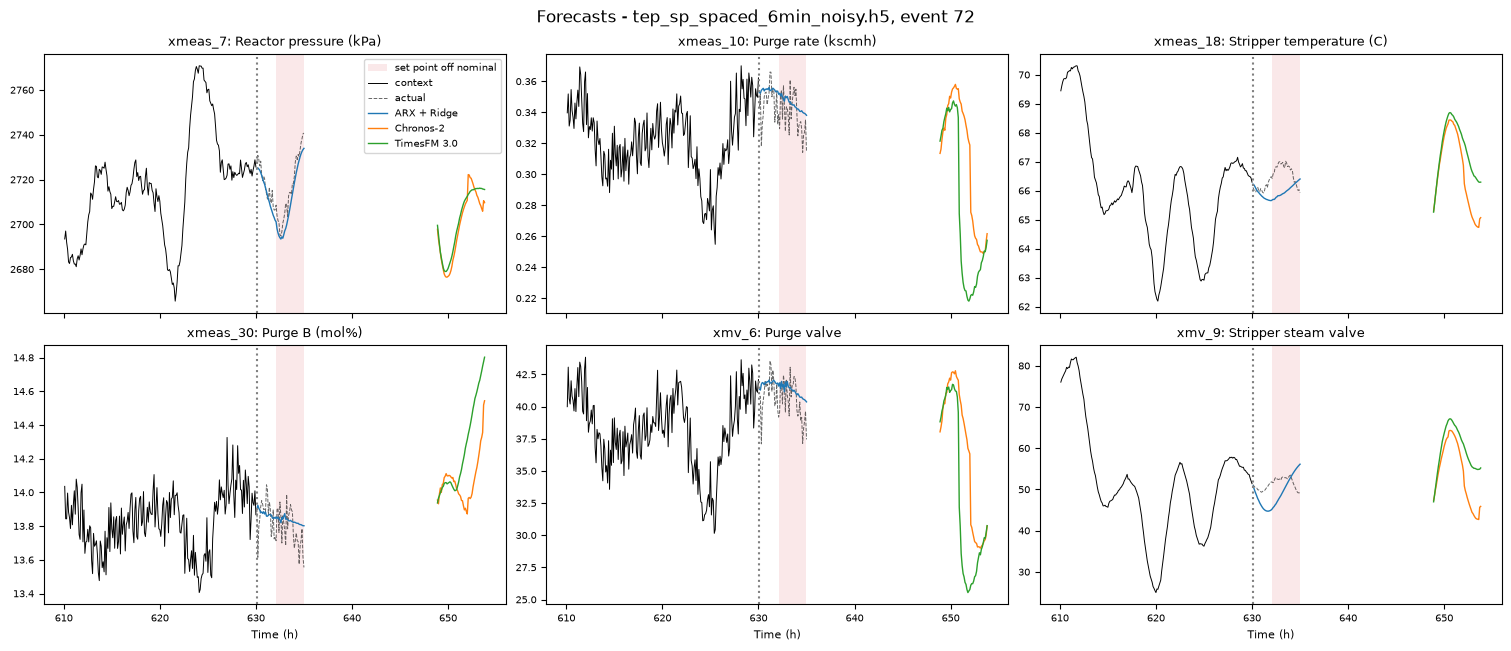

In [8]:
# Forecasts of a few variables, all models in one plot
PLOT_VARIABLES = ["xmeas_7", "xmeas_10", "xmeas_18", "xmeas_30", "xmv_6", "xmv_9"]
NCOLS = 3

ref = forecasts[first]
nrows = int(np.ceil(len(PLOT_VARIABLES) / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(5 * NCOLS, 3.2 * nrows), sharex=True, squeeze=False,
                         layout="constrained")
for ax, col in zip(axes.ravel(), PLOT_VARIABLES):
    ax.fill_between(ref["time_h"], 0, 1, where=ref["off_nominal"], color="tab:red", alpha=0.1,
                    transform=ax.get_xaxis_transform(), step="post", lw=0, label="set point off nominal")
    ax.plot(ref["context_time_h"], ref["context"][col], color="black", lw=0.7, label="context")
    ax.plot(ref["time_h"], ref["actual"][col], color="black", lw=0.7, ls="--", alpha=0.6, label="actual")
    for model in MODELS:
        ax.plot(forecasts[model]["time_h"], forecasts[model]["forecast"][col], color=COLORS[model], lw=1,
                label=model)
    ax.axvline(ref["time_h"][0], color="gray", ls=":")
    ax.set_title(f"{col}: {descriptions[col]}", fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(PLOT_VARIABLES):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("Time (h)", fontsize=8)
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"Forecasts - {settings[first]['data_file']}, event {settings[first]['event_index']}")
plt.show()
